# XGBoost

XGBoost (eXtreme Gradient Boosting) is a supervised machine learning algorithm used for classification and regression tasks. Instead of growing one large decision tree, it builds many small trees one after another. Each new tree is trained to correct the errors left by the trees before it, and the final prediction is all of those small corrections added together.

**Outcomes**:
- Explain how boosting builds a model by adding small trees that each correct the errors left so far
- Describe the difference between a single tree, a random forest (bagging), and boosting
- Fit `XGBRegressor` and `XGBClassifier` and score them on test rows
- Explain what `n_estimators`, `learning_rate`, and `max_depth` control
- Use a validation set and early stopping to choose the number of trees
- Use a grid search with cross-validation to compare settings
- Explain why the test rows are never used to choose settings
- Interpret feature importance, and explain why XGBoost is a blackbox model
- Recognize when a simpler model is the better choice

**Links**:
- [XGBoost Lab](xgboost.html): in-class simulation
- Diamond prices [template](template.ipynb). The diamonds data loads from seaborn, so there is no datafile to download.
- The last step of the template reuses the [affairs](/static/pages/course_model/ml10-dt/affairs.csv) dataset from the Decision Trees lesson

**Resources**:
- [Introduction to Boosted Trees](https://xgboost.readthedocs.io/en/stable/tutorials/model.html), from the XGBoost documentation
- [XGBoost parameters](https://xgboost.readthedocs.io/en/stable/parameter.html)
- [Random Forest](https://mlu-explain.github.io/random-forest/)
- [Train and Test and Validation](https://mlu-explain.github.io/train-test-validation/)
- [Cross Validation](https://mlu-explain.github.io/cross-validation/)

## Roadmap

Use this map to follow the code blocks below. Stages A to D are the same as in the Decision Trees lesson. Stage E is new: some of the training rows are held back so that XGBoost can check itself while it learns. The panel on the right shows what happens inside `.fit()`.

![XGBoost roadmap](xgboost-roadmap.svg)

## Overview

A single decision tree has to explain all of the data with one set of splits. XGBoost takes a different approach. It starts with one simple guess (the average), then adds a small tree that predicts how far off that guess is for each row. It adds another small tree to predict what is still wrong, and keeps going. Each tree is a weak model on its own. Hundreds of them added together are usually much more accurate than any single tree.

Key Concepts:

- XGBoost can predict either continuous (regression) or categorical (classification) outcomes.
- It is an *ensemble*: a model made by combining many smaller models.
- The trees are built in sequence. Each one is fit to the *errors* (actual minus predicted) left by the trees before it. This is called *boosting*.
- Only a fraction of each tree's correction is added to the prediction. That fraction is the *learning rate*.
- Like a single tree, XGBoost does not need scaled features, and it uses one-hot encoding for text columns.
- XGBoost can handle missing values on its own. At each split it learns which branch the rows with a missing value should follow.

Problems:

- Overfitting. If you keep adding trees, the model will eventually memorize the training rows.
    - Techniques to prevent this include using small trees, a small learning rate, and *early stopping*, which stops adding trees when a held-back set of rows stops improving.
- There are more settings to choose than with a single tree. Choosing them requires a validation set or cross-validation.
- It is a blackbox. You cannot print hundreds of trees and read them the way you read one small tree.
- On small or noisy datasets it may not beat a simple model, and it can do worse.

Interpretation:

- Overall model:
    - Feature importance shows which features did the most to reduce error across all of the trees. It does not tell you whether a feature raises or lowers the prediction.
    - Plotting the error after each tree for the training rows and the validation rows shows whether the model has started to memorize.
- Individual predictions:
    - A prediction is the starting guess plus the correction from every tree. There is no single path of splits to read.
    - We evaluate predictions with the same measures as before: MAE, RMSE and R² for numbers, and accuracy, precision, recall and a confusion matrix for categories.

## Topic: One tree, a forest, or boosting

There are two common ways to combine many trees.

*Bagging* builds many deep trees separately. Each tree sees a different random sample of the rows, so each one makes different mistakes. Averaging their predictions cancels out much of the error. A *random forest* is the best-known example. The trees do not depend on each other and could be built in any order.

*Boosting* builds small trees in sequence. Each tree depends on all of the trees before it, because it is trained on the errors they left behind. XGBoost is the best-known example.

| | Single tree | Random forest (bagging) | XGBoost (boosting) |
|---|---|---|---|
| Number of trees | 1 | Hundreds | Hundreds |
| Size of each tree | Small enough to read | Deep | Small |
| How trees are built | Once | Separately, each on a random sample of rows | In sequence, each on the errors left so far |
| How trees are combined | Not combined | Averaged | Added together |
| Main overfitting risk | A tree that is too deep | Low | Too many trees |
| Can you read it? | Yes (whitebox) | No (blackbox) | No (blackbox) |

## Topic: Learning from errors

Here is one round of boosting by hand, using four cars. The starting prediction for every car is the average mpg, which is 22.

| Car | Actual mpg | Start | Error | Tree 1 says | New prediction | New error |
|---|---|---|---|---|---|---|
| A (light) | 30 | 22 | +8 | +6 | 25 | +5 |
| B (light) | 26 | 22 | +4 | +6 | 25 | +1 |
| C (heavy) | 18 | 22 | -4 | -6 | 19 | -1 |
| D (heavy) | 14 | 22 | -8 | -6 | 19 | -5 |

1. Find the errors. The error is the actual value minus the prediction. Car A is 30 - 22 = +8.
2. Fit a small tree to the errors. This tree has one split: light cars or heavy cars. Each leaf predicts the average error of its rows, so the light leaf says (8 + 4) / 2 = +6 and the heavy leaf says -6.
3. Add a fraction of the tree to the prediction. With a learning rate of 0.5, car A moves from 22 to 22 + 0.5 × 6 = 25.

The errors are smaller than before, but they are not zero. The next tree is fit to the *new* errors (+5, +1, -1, -5), and the process repeats. Each tree only has to fix part of what is still wrong.

Two details are left out of this example. First, XGBoost shrinks each leaf's value a little (the `reg_lambda` setting), which makes it more cautious about leaves with only a few rows. Second, when predicting a category the same loop runs on probabilities: the error is the actual class (1 or 0) minus the predicted probability.

## Topic: The main settings

A setting that you choose before the model is fit is called a *hyperparameter*. These are the ones that matter most.

| Setting | What it controls | Default | Typical values |
|---|---|---|---|
| `n_estimators` | The number of trees | 100 | 100 to 1000 |
| `learning_rate` | The fraction of each tree's correction that is added | 0.3 | 0.01 to 0.3 |
| `max_depth` | How many levels of splits each tree may have | 6 | 2 to 6 |
| `early_stopping_rounds` | Stop when the validation rows have not improved for this many trees | off | 10 to 50 |
| `subsample` | The share of rows each tree sees | 1.0 | 0.5 to 1.0 |
| `colsample_bytree` | The share of columns each tree sees | 1.0 | 0.5 to 1.0 |
| `reg_lambda` | How strongly leaf values are shrunk toward zero | 1 | 0 to 10 |

The first three work together. A smaller learning rate takes smaller steps, so it needs more trees to reach the same place, but it is less likely to overshoot. Deeper trees can capture more complicated patterns in each step, but they memorize faster.

## Topic: Validation rows and early stopping

In the Decision Trees lesson we split the data into two parts: training rows and test rows. Now there are settings to choose, and that creates a problem. If we try many settings and keep the one that scores best on the test rows, the test score is no longer an honest estimate. We picked the settings *because* they did well on those particular rows.

The solution is to split the training rows again:

- The model learns from the *fit* rows.
- The *validation* rows are used to compare settings and to decide when to stop adding trees.
- The *test* rows are used once, at the very end.

*Early stopping* uses the validation rows while the model is being built. After each tree, XGBoost measures the error on the validation rows. When that error has not improved for a set number of trees, it stops, and it keeps the number of trees that had the lowest validation error.

*Cross-validation* is the other way to choose settings. Instead of one validation set, the training rows are split into five parts, and each part takes a turn as the validation rows. It takes longer, but it is more reliable when the dataset is small.

## Before you start

XGBoost is a separate library from scikit-learn. Install it once, then restart the kernel:

```python
%pip install xgboost
```

## Step 1: Load and Explore the Data

We use the same cars dataset as the Decision Trees lesson, so the results can be compared directly.

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

df = sns.load_dataset("mpg").dropna()

# Create a new column 'make' by splitting the 'name' column and taking the first word
df['make'] = df['name'].apply(lambda x: x.split(' ')[0])

df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name,make
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu,chevrolet
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320,buick
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite,plymouth
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst,amc
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino,ford
...,...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790,15.6,82,usa,ford mustang gl,ford
394,44.0,4,97.0,52.0,2130,24.6,82,europe,vw pickup,vw
395,32.0,4,135.0,84.0,2295,11.6,82,usa,dodge rampage,dodge
396,28.0,4,120.0,79.0,2625,18.6,82,usa,ford ranger,ford


## Step 2: Define predictors and target

The predictors, the target, the encoding and the train/test split are the same as in the Decision Trees lesson. The new part is the second split, which holds back 20% of the training rows as validation rows.

In [2]:
target = 'mpg'
numeric_features = ['weight', 'horsepower', 'displacement', 'acceleration', 'cylinders']
categorical_features = ['origin', 'make']

X = df[numeric_features + categorical_features]
y = df[target]

# One-Hot Encode the categorical predictors
X_encoded = pd.get_dummies(X, columns=categorical_features, drop_first=False)

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.25, random_state=42
)

# Hold back part of the training rows as validation rows.
# XGBoost will watch these rows to decide when to stop adding trees.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42
)

print("Rows to learn from:", len(X_fit))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

Rows to learn from: 235
Validation rows: 59
Test rows: 98


## Step 3: Baseline models

Before trying XGBoost, we need something to compare it to. The `score` function below measures a fitted model on the rows it learned from and on the test rows, and adds a line to a results table.

The first two models are the linear regression and the single decision tree from the Decision Trees lesson, and their test scores match that page. The third is a random forest.

In [3]:
results = []

def score(name, model, X_rows, y_rows):
    """Score a fitted model on the rows it learned from and on the test rows."""
    pred_train = model.predict(X_rows)
    pred_test = model.predict(X_test)
    results.append({
        'model': name,
        'train R^2': r2_score(y_rows, pred_train),
        'test R^2': r2_score(y_test, pred_test),
        'test RMSE': np.sqrt(mean_squared_error(y_test, pred_test)),
        'test MAE': mean_absolute_error(y_test, pred_test),
    })
    return pd.DataFrame(results).round(3)   # the results table so far

# Linear regression
linear = LinearRegression()
linear.fit(X_train, y_train)
score('Linear regression', linear, X_train, y_train)

# One decision tree
tree = DecisionTreeRegressor(random_state=42, max_depth=3, min_samples_leaf=5)
tree.fit(X_train, y_train)
score('Single tree (depth 3)', tree, X_train, y_train)

# A random forest: 300 deep trees, each grown on a random sample of the rows, then averaged
forest = RandomForestRegressor(n_estimators=300, random_state=42)
forest.fit(X_train, y_train)
score('Random forest (300 trees)', forest, X_train, y_train)

,model,train R^2,test R^2,test RMSE,test MAE
0,Linear regression,0.796,0.635,4.291,3.439
1,Single tree (depth 3),0.808,0.609,4.442,3.389
2,Random forest (300 trees),0.971,0.726,3.720,2.789


The single tree explains 61% of the variation in mpg on the test rows. Averaging 300 trees in a random forest raises that to 73%.

## Step 4: A first XGBoost model

`XGBRegressor` is used the same way as `DecisionTreeRegressor`: create it, `.fit()` it on the training rows, then `.predict()`. The three settings below are the defaults. They are written out so you can see them. `.tail(1)` shows only the newest line of the results table.

In [4]:
xgb_default = XGBRegressor(
    n_estimators=100,     # number of trees
    learning_rate=0.3,    # fraction of each tree's correction that is added
    max_depth=6,          # levels of splits allowed in each tree
    random_state=42
)
xgb_default.fit(X_train, y_train)

score('XGBoost (default settings)', xgb_default, X_train, y_train).tail(1)

,model,train R^2,test R^2,test RMSE,test MAE
3,XGBoost (default settings),1.0,0.737,3.643,2.686


With no tuning at all, XGBoost has the best test score so far: an R² of 0.737, and a typical miss (RMSE) of 3.6 mpg instead of the single tree's 4.4.

Now look at the training score. An R² of 1.0 means the model reproduces the mpg of every training car almost exactly. It has memorized them. The gap between 1.0 on the training rows and 0.737 on the test rows is the sign of overfitting, and it means the training score tells us nothing about how the model will do on new cars.

## Step 5: Watch it learn

XGBoost can report its error after every tree. Pass the rows you want it to score as `eval_set`. Here it learns from the fit rows and scores itself on both the fit rows and the validation rows.

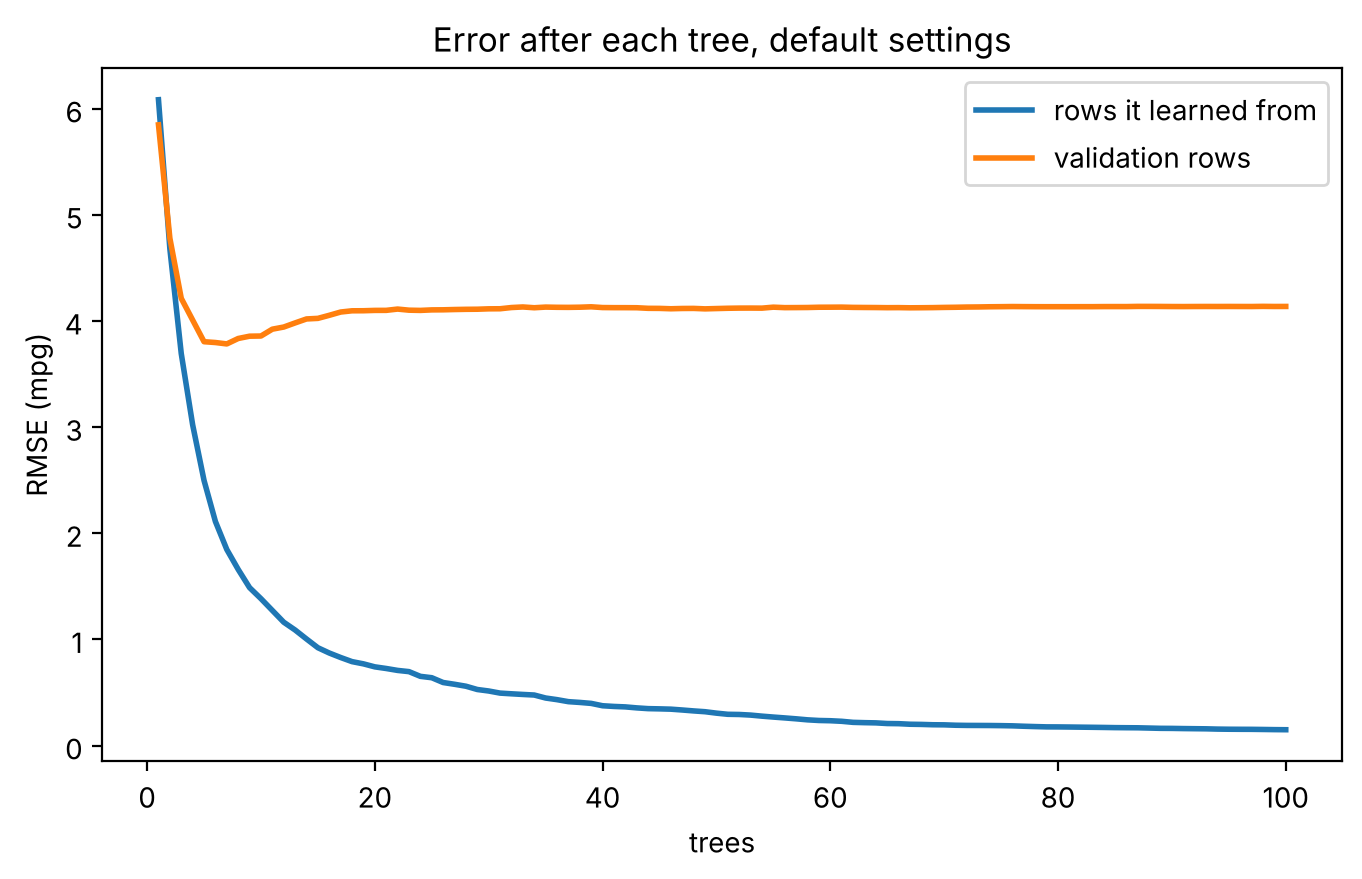

Lowest validation RMSE: 3.784 after 7 trees
Validation RMSE after 100 trees: 4.137
Training RMSE after 100 trees: 0.15


In [5]:
xgb_watch = XGBRegressor(n_estimators=100, learning_rate=0.3, max_depth=6, random_state=42)
xgb_watch.fit(
    X_fit, y_fit,
    eval_set=[(X_fit, y_fit), (X_val, y_val)],
    verbose=False
)

# evals_result() holds the RMSE after each tree.
# validation_0 is the first eval_set (the fit rows) and validation_1 is the second (the validation rows).
history = xgb_watch.evals_result()
curve = pd.DataFrame({
    'trees': range(1, 101),
    'rows it learned from': history['validation_0']['rmse'],
    'validation rows': history['validation_1']['rmse'],
})

curve.plot(x='trees', figsize=(8, 4.5), linewidth=2)
plt.ylabel('RMSE (mpg)')
plt.title('Error after each tree, default settings')
plt.show()

best = curve['validation rows'].idxmin()
print("Lowest validation RMSE:", round(curve['validation rows'][best], 3), "after", curve['trees'][best], "trees")
print("Validation RMSE after 100 trees:", round(curve['validation rows'].iloc[-1], 3))
print("Training RMSE after 100 trees:", round(curve['rows it learned from'].iloc[-1], 3))

The two lines tell different stories. On the rows the model learned from, the error keeps falling until it is close to zero. On the validation rows, the error is lowest after only 7 trees and then drifts back up. The other 93 trees did not make the model better at predicting cars it had not seen. They only memorized the cars it had.

## Step 6: Smaller steps and early stopping

Two changes make the model more careful: a smaller learning rate (0.05 instead of 0.3) and smaller trees (depth 2 instead of 6). Smaller steps need more trees, so we allow up to 1,000 and let early stopping decide how many to keep. `early_stopping_rounds=20` stops the model when the validation error has not improved for 20 trees in a row.

When there is more than one `eval_set`, early stopping watches the last one, so the validation rows go last.

Trees built before stopping: 80
Best number of trees: 60
Validation RMSE at that point: 3.843
Training RMSE at that point: 3.169


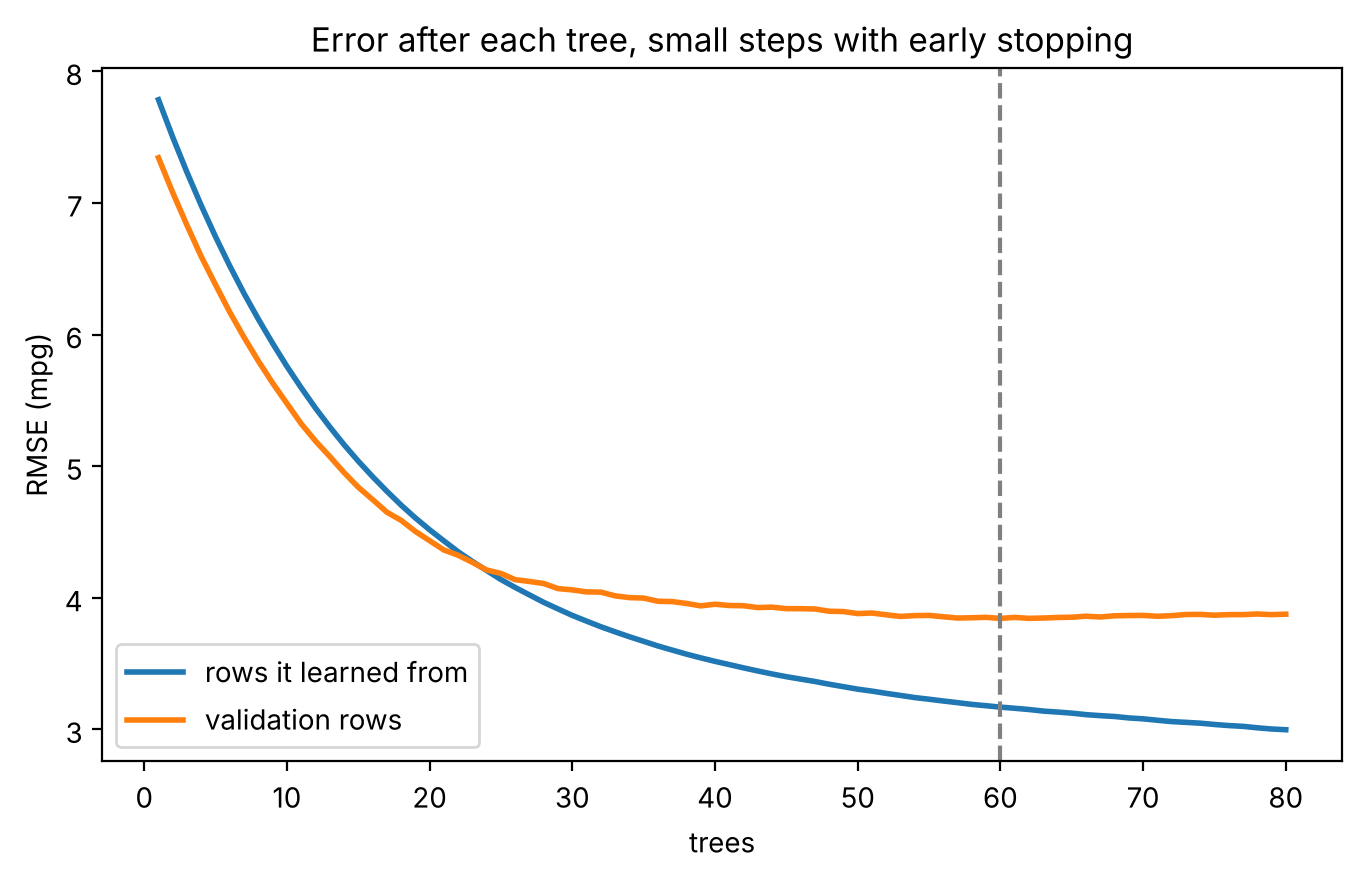

In [6]:
xgb_slow = XGBRegressor(
    n_estimators=1000,          # an upper limit; early stopping picks the real number
    learning_rate=0.05,         # smaller steps
    max_depth=2,                # smaller trees
    early_stopping_rounds=20,   # stop when 20 trees in a row fail to improve
    random_state=42
)
xgb_slow.fit(
    X_fit, y_fit,
    eval_set=[(X_fit, y_fit), (X_val, y_val)],
    verbose=False
)

history = xgb_slow.evals_result()
best_trees = xgb_slow.best_iteration + 1   # best_iteration counts from 0

print("Trees built before stopping:", len(history['validation_1']['rmse']))
print("Best number of trees:", best_trees)
print("Validation RMSE at that point:", round(xgb_slow.best_score, 3))
print("Training RMSE at that point:", round(history['validation_0']['rmse'][xgb_slow.best_iteration], 3))

curve = pd.DataFrame({
    'trees': range(1, len(history['validation_1']['rmse']) + 1),
    'rows it learned from': history['validation_0']['rmse'],
    'validation rows': history['validation_1']['rmse'],
})
curve.plot(x='trees', figsize=(8, 4.5), linewidth=2)
plt.axvline(best_trees, color='gray', linestyle='--')
plt.ylabel('RMSE (mpg)')
plt.title('Error after each tree, small steps with early stopping')
plt.show()

The model built 80 trees, saw that the last 20 had not helped, and kept the first 60. The two lines now stay much closer together: at 60 trees the training RMSE is 3.2 and the validation RMSE is 3.8. This model is learning patterns that carry over to new cars, rather than memorizing.

Early stopping told us how many trees to use. The last step is to fit a model with that many trees on *all* of the training rows, so that the validation rows are not wasted.

In [7]:
xgb_stopped = XGBRegressor(n_estimators=best_trees, learning_rate=0.05, max_depth=2, random_state=42)
xgb_stopped.fit(X_train, y_train)

score('XGBoost (small steps, early stopping)', xgb_stopped, X_train, y_train).tail(1)

,model,train R^2,test R^2,test RMSE,test MAE
4,"XGBoost (small steps, early stopping)",0.832,0.712,3.811,2.96


## Step 7: Compare settings with a grid search

We picked a learning rate of 0.05 and a depth of 2 by hand. A *grid search* tries every combination from a list of values and scores each one with cross-validation. The grid below has 4 × 3 × 4 = 48 combinations. With `cv=5`, each one is fit five times, for 240 models. On a dataset this small that takes well under a minute.

Only the training rows are used. The test rows stay out of it.

In [8]:
grid = GridSearchCV(
    XGBRegressor(random_state=42),
    param_grid={
        'n_estimators': [50, 100, 200, 400],
        'learning_rate': [0.3, 0.1, 0.05],
        'max_depth': [1, 2, 3, 6],
    },
    cv=5,
    scoring='neg_root_mean_squared_error'
)
grid.fit(X_train, y_train)

print("Best settings:", grid.best_params_)
print("Cross-validated RMSE:", round(-grid.best_score_, 3))

# The five best combinations. scikit-learn reports the RMSE as a negative number, so flip the sign.
tried = pd.DataFrame(grid.cv_results_)
tried['cv RMSE'] = -tried['mean_test_score']
tried = tried.rename(columns={
    'param_n_estimators': 'n_estimators',
    'param_learning_rate': 'learning_rate',
    'param_max_depth': 'max_depth'
})
tried.sort_values('cv RMSE')[['n_estimators', 'learning_rate', 'max_depth', 'cv RMSE']].head(5).round(3)

Best settings: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
Cross-validated RMSE: 3.704


,n_estimators,learning_rate,max_depth,cv RMSE
41,100,0.05,3,3.704
24,50,0.10,3,3.717
42,200,0.05,3,3.728
25,100,0.10,3,3.761
44,50,0.05,6,3.771


The best combinations are nearly tied, and most of them pair a small learning rate with trees of depth 3. After a grid search, `best_estimator_` is the winning model, already refit on all of the training rows.

In [9]:
xgb_tuned = grid.best_estimator_

score('XGBoost (grid search)', xgb_tuned, X_train, y_train).tail(1)

,model,train R^2,test R^2,test RMSE,test MAE
5,XGBoost (grid search),0.905,0.724,3.728,2.929


## Step 8: Compare the models

The results table now holds all six models. The chart shows their R² on the test rows.

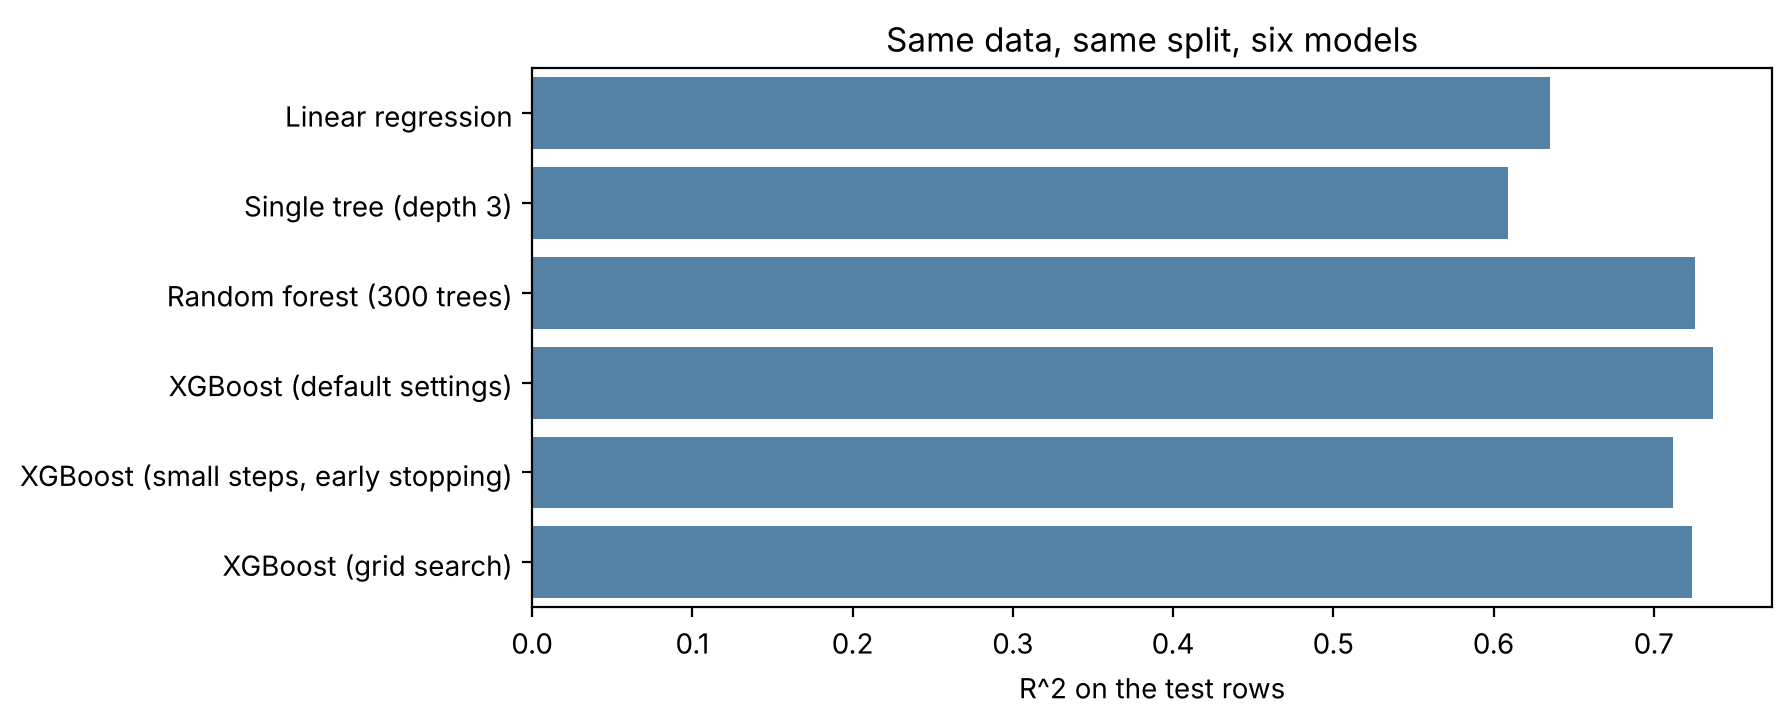

,model,train R^2,test R^2,test RMSE,test MAE
0,Linear regression,0.796,0.635,4.291,3.439
1,Single tree (depth 3),0.808,0.609,4.442,3.389
2,Random forest (300 trees),0.971,0.726,3.720,2.789
3,XGBoost (default settings),1.000,0.737,3.643,2.686
4,"XGBoost (small steps, early stopping)",0.832,0.712,3.811,2.960
5,XGBoost (grid search),0.905,0.724,3.728,2.929


In [10]:
summary = pd.DataFrame(results).round(3)

plt.figure(figsize=(8, 3.5))
sns.barplot(data=summary, y='model', x='test R^2', color='steelblue')
plt.xlabel('R^2 on the test rows')
plt.ylabel('')
plt.title('Same data, same split, six models')
plt.show()

summary

What the comparison shows:

- Every model built from many trees beats the single tree by a wide margin. The test R² rises from 0.61 to between 0.71 and 0.74, and the typical miss falls from 4.4 mpg to about 3.7.
- The four ensembles are too close to rank. There are only 98 test cars, and a difference of 0.02 in R² is well within what a different random split would produce. On this data, a random forest does as well as XGBoost.
- Tuning did not raise the test score. What it changed is the gap between training and test. The default model scores 1.000 on the rows it learned from, which says nothing about how it will do on new cars. The early-stopping model scores 0.832 in training and 0.712 in testing, a far more honest picture.
- This is a small dataset with 392 cars. The assignment uses one with 53,940 rows, where the same steps have more to work with.

## Step 9: Read the model

There is no single tree to plot, so we rely on feature importance. As with a single tree, it is each feature's share of the total error reduction, now added up across every tree.

In [11]:
importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': xgb_tuned.feature_importances_
}).sort_values('importance', ascending=False)

importance.head(8).round(3)

,feature,importance
2,displacement,0.341
4,cylinders,0.198
0,weight,0.098
1,horsepower,0.079
30,make_oldsmobile,0.053
6,origin_japan,0.028
15,make_chevrolet,0.027
44,make_vw,0.026


The single tree in the Decision Trees lesson used only four features and put 76% of the importance on displacement. XGBoost spreads the importance across more features, because each new tree is free to use whichever feature best explains the errors that are left. Displacement, cylinders, weight and horsepower all measure roughly the same thing (a big engine in a heavy car), so the importance is shared among them. Be careful about ranking features that are closely related.

We can also watch a prediction being built. `iteration_range=(0, n)` asks for the prediction using only the first `n` trees, so the column `after 10` is the prediction after 10 trees. The two cars below are a heavy station wagon and a light hatchback.

In [12]:
# Rows 6 and 2 of the test set: a heavy wagon and a light hatchback
cars = X_test.iloc[[6, 2]]

steps = {'actual mpg': y_test.iloc[[6, 2]].values}
for n in [1, 5, 10, 25, 50, xgb_tuned.n_estimators]:
    steps['after ' + str(n)] = xgb_tuned.predict(cars, iteration_range=(0, n))

print("Starting guess (average mpg of the training rows):", round(y_train.mean(), 2))
pd.DataFrame(steps, index=df.loc[cars.index, 'name']).astype(float).round(1)

Starting guess (average mpg of the training rows): 23.69


,actual mpg,after 1,after 5,after 10,after 25,after 50,after 100
name,,,,,,,
ford country squire (sw),13.0,23.2,21.5,19.7,16.4,13.9,13.1
honda civic cvcc,36.1,24.2,26.0,27.9,31.5,33.5,34.4


Both cars start near the average of 23.7 mpg. With a learning rate of 0.05, each tree moves the prediction only a little, and the two cars move in opposite directions as the corrections add up. These two cars were picked because they are far from the average, which makes the steps easy to see. Across all of the test cars, the typical miss is still about 3 mpg.

## Alternative: Predict a class variable

`XGBClassifier` predicts a category. As in the Decision Trees lesson, we predict each car's origin from its other features.

There is one extra step. XGBoost needs the classes as the numbers 0, 1, 2 rather than as text, so we convert them with `LabelEncoder` and convert the predictions back afterward.

Classes: {'europe': 0, 'japan': 1, 'usa': 2}


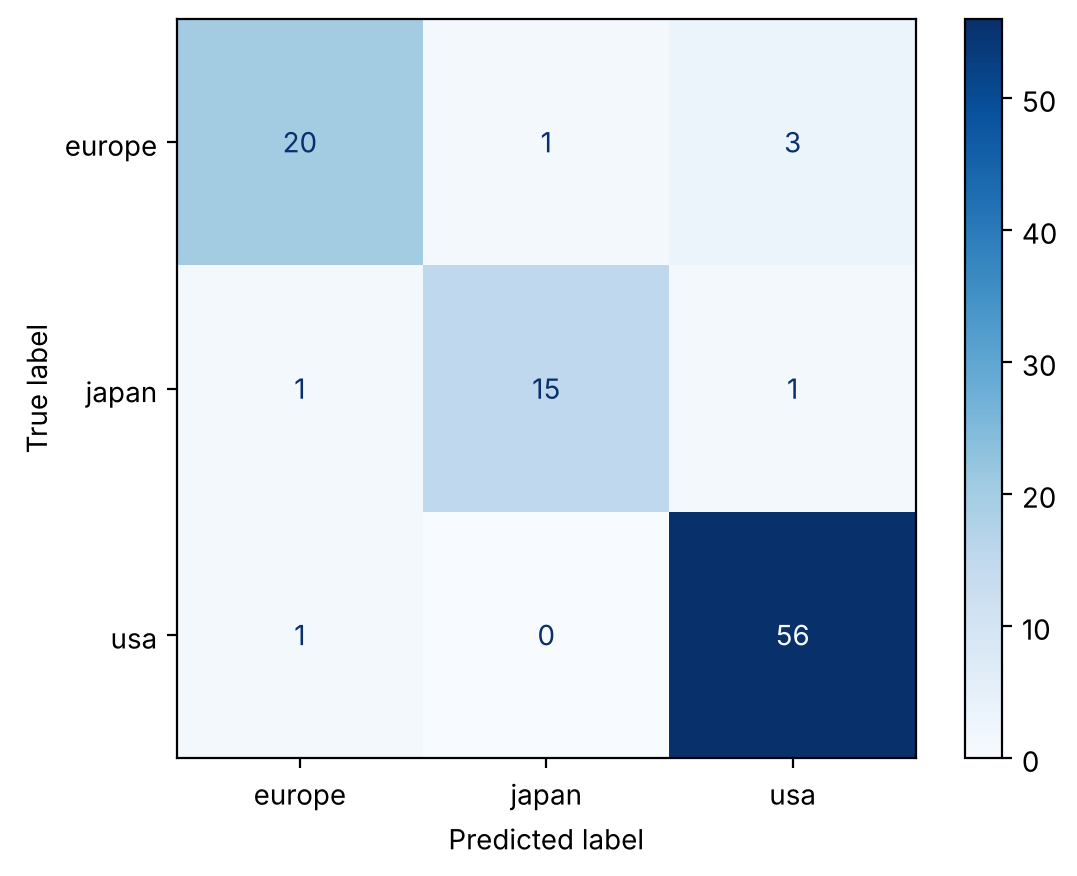

Accuracy: 0.9285714285714286
Confusion Matrix:
 [[20  1  3]
 [ 1 15  1]
 [ 1  0 56]]


In [13]:
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBClassifier

numeric_features = ['weight', 'horsepower', 'displacement', 'acceleration', 'cylinders', 'model_year']
categorical_features = ['make']

X = df[numeric_features + categorical_features]
y = df['origin']

# One-hot encode
X_encoded = pd.get_dummies(X, columns=categorical_features, drop_first=False)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.25, random_state=42
)

# Convert the text classes to numbers
encoder = LabelEncoder()
y_train_num = encoder.fit_transform(y_train)
print("Classes:", dict(zip(encoder.classes_, range(len(encoder.classes_)))))

clf = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
clf.fit(X_train, y_train_num)

# Predictions come back as numbers, so convert them back to text labels
y_pred = encoder.inverse_transform(clf.predict(X_test))

acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=encoder.classes_, cmap='Blues')
plt.show()

print("Accuracy:", acc)
print("Confusion Matrix:\n", cm)

The single tree in the Decision Trees lesson classified 80 of the 98 test cars correctly (0.816). XGBoost gets 91 of 98 (0.929). Most of the improvement is in the japan row: the single tree found 9 of the 17 japanese cars, and XGBoost finds 15.

A classifier can also report how confident it is. `predict_proba` returns one probability for each class, and the predicted class is the one with the highest probability.

In [14]:
proba = pd.DataFrame(clf.predict_proba(X_test), columns=encoder.classes_).round(3)
proba['predicted'] = y_pred
proba['actual'] = y_test.values

proba.head(8)

,europe,japan,usa,predicted,actual
0,0.513,0.382,0.105,europe,europe
1,0.756,0.100,0.143,europe,europe
2,0.027,0.966,0.007,japan,japan
3,0.493,0.116,0.391,europe,usa
4,0.005,0.004,0.991,usa,usa
5,0.040,0.948,0.012,japan,japan
6,0.001,0.001,0.998,usa,usa
7,0.032,0.959,0.008,japan,japan


Row 3 is the one mistake shown here, and the probabilities explain it: 0.49 for europe against 0.39 for usa. The model was unsure. Compare that with row 4, where it gives usa a probability of 0.99.

## Your Turn

1. The regression above leaves out `model_year`. Add it to `numeric_features` in Step 2 and run Steps 2 through 8 again. Which models improve? Does the new column help more or less than the tuning did?
2. In Step 6, change `learning_rate` to 0.3 and then to 0.01. How does the best number of trees change?
3. In Step 6, change `early_stopping_rounds` to 5. Does the model stop sooner? Is the validation RMSE better or worse?
4. In Step 4, set `max_depth=1`. A tree with one split is called a stump. How does the gap between the training and test R² change?
5. Open the [XGBoost Lab](xgboost.html) and work through the activities.

## Key Terms

- **XGBoost**: A library that builds a model from many small decision trees added in sequence, each one correcting the errors left by the trees before it
- **Ensemble**: A model made by combining the predictions of many smaller models
- **Boosting**: Building models in sequence, where each new model is trained on the errors left by the ones before it
- **Gradient boosting**: The form of boosting used by XGBoost, where each new tree is fit to the direction that reduces the error fastest; for a numeric outcome that is the residual
- **Bagging**: Building many models separately, each on a random sample of the rows, and averaging their predictions
- **Random forest**: A bagging ensemble of deep decision trees (`RandomForestRegressor`, `RandomForestClassifier`)
- **Residual (error)**: The actual value minus the predicted value for one row
- **Weak learner**: A simple model, such as a very small tree, that is only a little better than guessing on its own
- **Stump**: A decision tree with a single split (`max_depth=1`)
- **Number of trees**: How many trees the model builds, one per round of boosting (`n_estimators`)
- **Learning rate**: The fraction of each new tree's correction that is added to the prediction (`learning_rate`)
- **Hyperparameter**: A setting chosen before the model is fit, such as the learning rate or the tree depth
- **Validation set**: Rows held back from the training rows and used to compare settings or decide when to stop, so that the test rows stay untouched
- **Early stopping**: Ending training when the error on the validation rows has not improved for a set number of trees (`early_stopping_rounds`)
- **Learning curve**: A plot of the error after each tree for the training rows and the validation rows
- **Grid search**: Trying every combination from a list of settings and keeping the one with the best cross-validated score (`GridSearchCV`)
- **Regularization**: Settings that hold a model back from fitting the training rows too closely, such as shrinking leaf values (`reg_lambda`)
- **Subsampling**: Letting each tree see only a random share of the rows or columns (`subsample`, `colsample_bytree`)
- **Label encoding**: Converting text classes to the numbers 0, 1, 2 so that `XGBClassifier` can use them (`LabelEncoder`)
- **Predicted probability**: A classifier's estimate of how likely a row is to belong to each class (`predict_proba`)
- **Feature importance**: Each feature's share of the total error reduction across all of the trees

## Practice Questions

1. How does XGBoost build its model?
   - It adds many small trees one at a time, each correcting the errors left by the trees before it
   - It grows one very deep tree until every leaf is pure
   - It fits a straight line through the data
   - It groups similar rows together without using an outcome
1. In boosting, what is each new tree trained to predict?
   - The errors left by the current prediction
   - The original outcome, starting over from scratch
   - A random sample of the outcome
   - The cluster each row belongs to
1. What prediction does XGBoost start with before any tree is added to a regression?
   - The average of the outcome in the training rows
   - Zero for every row
   - The outcome of the first row
   - A random number for each row
1. A car's actual mpg is 30 and the current prediction is 22. What error will the next tree try to predict for this car?
   - +8, because 30 - 22
   - -8
   - 52
   - 22
1. The current prediction for a car is 22. The new tree's leaf says +6, and the learning rate is 0.5. What is the new prediction?
   - 25, because 22 + 0.5 × 6
   - 28
   - 22.5
   - 19
1. The current prediction is 20, the new tree says +4, and `learning_rate=0.1`. What is the new prediction?
   - 20.4
   - 24
   - 20.04
   - 16
1. What does `learning_rate` control?
   - The fraction of each tree's correction that is added to the prediction
   - The number of trees in the model
   - The share of rows used for testing
   - How many levels of splits each tree may have
1. You lower the learning rate from 0.3 to 0.05. What usually has to change?
   - The model needs more trees, because each one moves the prediction less
   - The model needs fewer trees, because each one now does more of the work
   - The numeric features must be scaled before the model is fit
   - The test set must be made larger to make up for it
1. What does `n_estimators` set?
   - The number of trees
   - The depth of each tree
   - The number of features
   - The number of validation rows
1. How is a random forest different from XGBoost?
   - Its trees are built separately on random samples of rows and averaged; XGBoost's trees are built in sequence, each on the errors left so far
   - It grows a single very deep tree; XGBoost grows many small trees and keeps only the best one
   - It can only predict categories; XGBoost can only predict numbers
   - It needs scaled features because it averages its trees; XGBoost does not
1. Why does boosting usually work well with small trees?
   - Each tree only has to make a small correction, and many small corrections add up
   - Small trees are the only kind that can use numeric features
   - Small trees never make errors
   - Large trees cannot be combined
1. What are the validation rows used for in this lesson?
   - Checking the model while it trains and choosing settings, so the test rows stay untouched
   - Fitting the trees, in place of the training rows
   - Reporting the final score once the model is finished
   - Filling in rows where the outcome is missing
1. Why should you not use the test rows to choose the number of trees?
   - The test score would no longer be an honest estimate of how the model does on new data
   - The test set is too large to be scored more than once
   - XGBoost cannot make predictions for rows it was not trained on
   - It would make the model take much longer to fit
1. What does `early_stopping_rounds=20` do?
   - Stops adding trees once the validation error has not improved for 20 trees in a row
   - Limits the model to a total of 20 trees, however well it is doing
   - Holds back 20 of the training rows to use as validation rows
   - Stops training 20 trees after the training error reaches zero
1. With the default settings, the training RMSE kept falling to 0.15 while the validation RMSE was lowest at 7 trees and then rose. What does this show?
   - Overfitting: the later trees memorized the training rows without improving predictions for new rows
   - Underfitting: the model needed many more trees to learn the pattern
   - The validation set was too large for the model to score well on it
   - The learning rate was too small for the model to make progress
1. `best_iteration` is 59. How many trees does that model use?
   - 60, because the count starts at 0
   - 59
   - 58
   - 118
1. A model has a training R² of 1.000 and a test R² of 0.737. What is the best reading of this?
   - It has memorized the training rows, so only the test score tells you how it will do on new data
   - It will predict new data almost perfectly, because the training score is the one that matters
   - The test rows must contain errors, since the training score is perfect
   - It is underfit and needs more trees to close the gap
1. What does `GridSearchCV` do?
   - Tries every combination of the listed settings and scores each one with cross-validation
   - Removes the features with the lowest importance and fits the model again
   - Splits the data into training, validation and test rows
   - Plots every tree in the model so that their splits can be compared
1. A grid has 4 values of `n_estimators`, 3 of `learning_rate`, and 4 of `max_depth`, and uses `cv=5`. How many models are fit during the search?
   - 240, because 48 combinations × 5 folds
   - 48
   - 55
   - 11
1. Do you need to scale numeric features before using XGBoost?
   - No, it is built from trees, and each split only compares one feature to a cutoff
   - Yes, because boosting measures the distance between rows
   - Yes, but only when it is predicting a category
   - Only when the learning rate is below 0.1
1. Why do we use `LabelEncoder` before fitting `XGBClassifier` on the car origins?
   - XGBoost needs the classes as the numbers 0, 1, 2 rather than as text
   - To scale the features
   - To one-hot encode the predictors
   - To split the data into training and test rows
1. A classifier's `predict_proba` gives a car 0.49 for europe, 0.12 for japan, and 0.39 for usa. What does it predict, and how confident is it?
   - europe, but it is not confident because usa is close behind
   - usa, with high confidence
   - europe, with near certainty
   - japan, because it has the lowest probability
1. What does feature importance tell you about an XGBoost model?
   - Which features did the most to reduce error across all of the trees
   - Whether each feature raises or lowers the prediction
   - The p-value of each feature
   - The exact rule used for each prediction
1. Why is XGBoost considered a blackbox model?
   - A prediction is the sum of hundreds of trees, which cannot be read the way one small tree can
   - The library's code is secret, so nobody can see how it works
   - It ignores the features and predicts from the outcome alone
   - Its predictions cannot be scored on a test set
1. In the mpg comparison, which conclusion is best supported?
   - The models built from many trees clearly beat the single tree, but they were too close to each other to rank
   - XGBoost with tuned settings was far better than every other model
   - The single tree was the most accurate model
   - Linear regression beat the random forest
1. When might a simpler model be a better choice than XGBoost?
   - When the dataset is small or noisy, or when you must be able to explain how each prediction was made
   - When the dataset has more than 10,000 rows, because XGBoost cannot handle that many
   - When the outcome is a number instead of a category
   - When some of the predictors are text columns